# Proyecto Oráculo · Notebook de búsqueda · Grupo G01

**Análisis y Diseño de Algoritmos · Universidad de Caldas · 2026-2** — Juan Manuel Carmona Villegas

Este notebook documenta cómo se obtuvo la configuración de `entrega.json`. El método combina tres ideas:

1. **Cribado:** medir cada opción sola para conocer su efecto aislado.
2. **Poda guiada por trazas:** descartar las opciones que bajan la precisión o que rompen alguna familia de restricciones.
3. **Ascenso por coordenadas:** mejorar la configuración cambiando una ranura a la vez hasta que ningún cambio mejore.

Todas las evaluaciones usan las mismas 100 instancias de búsqueda y la semilla 1, para que las precisiones sean comparables. El resultado es la **mejor configuración encontrada**, no un óptimo global demostrado.

## 1 · Instalación y archivos del curso

Instala las librerías del modelo y de los verificadores de restricciones (`open-instruct`) y descarga `oraculo.py`, `ayudas.py` y `datos_visibles.json`. **Al terminar hay que reiniciar el entorno** (*Entorno de ejecución ▸ Reiniciar sesión*) y seguir desde la celda 2, sin volver a correr esta.

In [1]:
# bitsandbytes: checkpoints 4-bit (qwen8b, mistral7b). nltk/spacy/emoji/langdetect:
# los usa el verificador de open-instruct, no el notebook.
!pip install -q -U "bitsandbytes>=0.46.1" transformers accelerate \
                   nltk spacy emoji langdetect immutabledict
!python -m spacy download en_core_web_sm -q
!git clone -q https://github.com/allenai/open-instruct

REPO = "https://raw.githubusercontent.com/DanielMelo404/Proyecto-Oraculo-AyD/main"
# --no-cache: Colab a veces reusa un ayudas.py viejo y el alias no existe.
!wget -q --no-cache -O oraculo.py {REPO}/oraculo.py
!wget -q --no-cache -O ayudas.py {REPO}/ayudas.py
!wget -q --no-cache -O datos_visibles.json {REPO}/datos_visibles.json

# Los datos de nltk se bajan a mano: su downloader rechaza el proxy de Colab.
import io
import urllib.request
import zipfile

NLTK_DATA = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages"
PAQUETES = [
    ("tokenizers", "punkt"),
    ("tokenizers", "punkt_tab"),
    ("taggers", "averaged_perceptron_tagger"),
    ("taggers", "averaged_perceptron_tagger_eng"),
]
for carpeta, nombre in PAQUETES:
    with urllib.request.urlopen(f"{NLTK_DATA}/{carpeta}/{nombre}.zip") as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(f"/root/nltk_data/{carpeta}")

print("LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2


## 2 · El modelo

Se usa `qwen17b` (Qwen/Qwen3-1.7B en fp16), el modelo por defecto del curso, en una GPU T4 (*Entorno de ejecución ▸ Cambiar tipo de entorno de ejecución ▸ T4 GPU*). El nombre del modelo forma parte de la clave del caché.

In [1]:
from ayudas import cargar_modelo

# Alias → checkpoint. El nombre entra en la clave de caché: si cambian de
# modelo, las respuestas anteriores no se reusan.
#  "qwen17b"     → Qwen/Qwen3-1.7B
#  "ministral3b" → mistralai/Ministral-3-3B-Instruct-2512-BF16
#  "llama3b"     → unsloth/Llama-3.2-3B-Instruct
modelo = cargar_modelo("qwen17b")


cargando qwen17b → Qwen/Qwen3-1.7B


Qwen/Qwen3-1.7B  VRAM: 3.44 GB


## 3 · El oráculo, los datos y el caché

`dividir` separa `datos_visibles.json` en **100 instancias de búsqueda** (2,5 restricciones por instancia) y **87 de validación** (2,4); las 263 restantes vienen marcadas como descartadas. La búsqueda usa solo `busqueda`; `validacion` se usa únicamente al final.

El caché del oráculo se guarda en Google Drive (`oraculo_cache.json`): si Colab se desconecta, lo ya generado no se vuelve a pagar. Por eso, en esta ejecución, las evaluaciones ya calculadas en sesiones anteriores aparecen con `(0 s)`.

`espacio()` genera las 8⁵ = 32 768 configuraciones posibles con temperatura 0.0.

In [3]:
# Conectar Google Drive para que el caché NO se pierda si Colab se desconecta
from google.colab import drive
drive.mount("/content/drive")

from oraculo import Oraculo, CATALOGO, espacio
from ayudas import cargar_datos, dividir

datos = cargar_datos()
busqueda, validacion = dividir(datos)

oraculo = Oraculo(modelo, busqueda, validacion,
                  cache="/content/drive/MyDrive/oraculo_cache.json",
                  lote=16, presupuesto=32_000_000)

CONFIGS = espacio()
print(len(CONFIGS), "configuraciones posibles")
print(len(busqueda), "instancias de búsqueda |", len(validacion), "de validación")


Mounted at /content/drive
450 instancias, 2.3 restricciones por instancia
búsqueda: 100 inst, 2.5 restr/inst
validación: 87 inst, 2.4 restr/inst
(263 instancias descartadas: no medían nada — ver `dividir`)
modo pensamiento: apagado
caché: 9600 respuestas recuperadas
32768 configuraciones posibles
100 instancias de búsqueda | 87 de validación


## Línea base y costo de una evaluación

Se mide el prompt **sin ninguna instrucción adicional**. Resultado: **16 %** de precisión (16 de 100 instancias).

En la primera ejecución (sin caché), esta evaluación tardó **3,2 minutos** en la GPU T4; en la ejecución guardada aquí sale 0,0 minutos porque la respuesta viene del caché. Las evaluaciones nuevas de la Fase 3 confirman el costo: unos 205 segundos cada una.

Con ese costo, probar las 32 768 configuraciones tomaría 32 768 × 3,2 min ≈ 73 días de GPU. Por eso se necesita una búsqueda que use pocas evaluaciones.

In [4]:
import time

# Configuración vacía = el prompt SIN ninguna instrucción extra.
# Es nuestro punto de partida (la "línea base") para comparar todo lo demás.
base = {"temperatura": 0.0}

t0 = time.time()
r = oraculo.evaluar(base, busqueda, semilla=1)
segundos = time.time() - t0

print(f"Precisión sin instrucciones: {r.precision:.1%}")
print(f"Tiempo de UNA evaluación (100 instancias): {segundos/60:.1f} minutos")

# Ver 3 fallos: qué restricción se violó y qué respondió el modelo
for t in r.trazas[:3]:
    print("\nviolo:", t["violo"])
    print(t["salida"][:200])

Precisión sin instrucciones: 16.0%
Tiempo de UNA evaluación (100 instancias): 0.0 minutos

violo: letters:letter_counting2
<<Top 5 Universities in South Africa>>

1. University of Cape Town  
2. Stellenbosch University  
3. University of Johannesburg  
4. University of Pretoria  
5. University of the Witwatersrand  

Is t

violo: paragraphs:paragraphs
def analyze_project_progress(projects):
    if not projects:
        return {
            'average_completion': 0,
            'high_priority_average': 0,
            'count_completed': 0
        }
  

violo: startend:quotation
The stranger's love story spread through multiple cities, with each city's visit contributing to a growing number of listeners. In the first city, the stranger shared the story with 5 people each day 


## Herramientas: medir y registrar

`medir(config, fase, nota)` evalúa una configuración sobre las 100 instancias de búsqueda y guarda en `registro` una fila con la configuración, la precisión, el tiempo y las tres familias de restricciones más violadas (obtenidas de las trazas). `guardar_registro()` exporta ese registro a `registro_busqueda.csv`, que es la tabla de todas las configuraciones evaluadas.

In [5]:
# ═══ CELDA A · Herramientas: medir una configuración y llevar el registro ═══
import csv, time
from collections import Counter

RANURAS = ["rol", "estrategia", "formato", "estilo", "cierre"]
INSTANCIAS = busqueda        # SIEMPRE las mismas 100 instancias: así las precisiones son comparables
SEMILLA = 1                  # semilla fija = resultados reproducibles
RUTA_REGISTRO = "/content/drive/MyDrive/registro_busqueda.csv"

registro = []    # una fila por cada configuración evaluada (la evidencia que pide la guía)
historial = []   # solo las precisiones, en orden, para dibujar curva(historial)

def texto(config):
    """Escribe la config en corto, p. ej. 'rol=3 estr=- form=- esti=- cier=-'."""
    return " ".join(f"{s[:4]}={config.get(s, '-')}" for s in RANURAS)

def medir(config, fase, nota=""):
    """Evalúa UNA configuración sobre las 100 instancias y la anota en el registro.
    Devuelve (precisión, Counter con cuántas veces falló cada familia de restricción)."""
    t0 = time.time()
    r = oraculo.evaluar(config, INSTANCIAS, semilla=SEMILLA)
    fallos = Counter(t["violo"] for t in r.trazas)   # trazas = solo las instancias que fallaron
    fila = {"n": len(registro) + 1, "fase": fase,
            **{s: config.get(s, "-") for s in RANURAS},
            "temperatura": config["temperatura"],
            "precision": r.precision,
            "segundos": round(time.time() - t0, 1),
            "top_fallos": "; ".join(f"{f} x{c}" for f, c in fallos.most_common(3)),
            "nota": nota}
    registro.append(fila)
    historial.append(r.precision)
    print(f"#{fila['n']:3d} [{fase}] {texto(config)} -> {r.precision:5.1%}  ({fila['segundos']:.0f} s) {nota}")
    return r.precision, fallos

def guardar_registro():
    """Copia el registro a Drive como CSV (sobrevive a desconexiones)."""
    with open(RUTA_REGISTRO, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(registro[0].keys()))
        w.writeheader()
        w.writerows(registro)

print("Herramientas listas")

Herramientas listas


## Fase 1 · Cribado (40 evaluaciones)

Cada una de las 40 opciones (5 ranuras × 8 opciones) se evalúa **sola**, con las demás ranuras vacías. Así se observa el efecto aislado de cada opción y qué familias de restricciones daña.

Resultado: solo unas 10 de las 40 opciones superan la línea base. En `formato` y `cierre` hay una única opción que no empeora (formato 0 con 18 % y cierre 3 con 18 %).

In [6]:
# ═══ CELDA B · Fase 0 (línea base) y Fase 1 (cribado: cada opción por separado) ═══
BASE = {"temperatura": 0.0}
p_base, f_base = medir(BASE, "0-base", "sin instrucciones")

cribado = {}   # (ranura, opción) -> (precisión, fallos)
for s in RANURAS:
    for o in range(8):
        config = {s: o, "temperatura": 0.0}   # SOLO esta ranura activa; las demás vacías
        cribado[(s, o)] = medir(config, "1-cribado", f"{s}={o}")
    guardar_registro()                         # guarda al terminar cada ranura

print(f"\nCribado terminado: {len(cribado)} evaluaciones. Línea base = {p_base:.1%}")

#  1 [0-base] rol=- estr=- form=- esti=- cier=- -> 16.0%  (0 s) sin instrucciones
#  2 [1-cribado] rol=0 estr=- form=- esti=- cier=- -> 15.0%  (0 s) rol=0
#  3 [1-cribado] rol=1 estr=- form=- esti=- cier=- -> 16.0%  (0 s) rol=1
#  4 [1-cribado] rol=2 estr=- form=- esti=- cier=- -> 18.0%  (0 s) rol=2
#  5 [1-cribado] rol=3 estr=- form=- esti=- cier=- -> 18.0%  (0 s) rol=3
#  6 [1-cribado] rol=4 estr=- form=- esti=- cier=- -> 11.0%  (0 s) rol=4
#  7 [1-cribado] rol=5 estr=- form=- esti=- cier=- -> 14.0%  (0 s) rol=5
#  8 [1-cribado] rol=6 estr=- form=- esti=- cier=- -> 15.0%  (0 s) rol=6
#  9 [1-cribado] rol=7 estr=- form=- esti=- cier=- -> 13.0%  (0 s) rol=7
# 10 [1-cribado] rol=- estr=0 form=- esti=- cier=- -> 12.0%  (0 s) estrategia=0
# 11 [1-cribado] rol=- estr=1 form=- esti=- cier=- -> 11.0%  (0 s) estrategia=1
# 12 [1-cribado] rol=- estr=2 form=- esti=- cier=- -> 16.0%  (0 s) estrategia=2
# 13 [1-cribado] rol=- estr=3 form=- esti=- cier=- -> 15.0%  (0 s) estrategia=3
# 14 [1-cribad

## Poda guiada por trazas

Una opción se **descarta** si cumple alguno de estos criterios:

- Su precisión queda más de 2 puntos por debajo de la línea base (`TOLERANCIA = 0.02`).
- Según las trazas, aumenta en 3 o más los fallos de alguna familia de restricciones respecto a la línea base (`UMBRAL = 3`). Ejemplo: `rol=1` se descartó porque aumentó los fallos de `keywords:frequency`.

De las sobrevivientes se conservan como máximo 3 por ranura (`TOP = 3`), ordenadas por precisión. El espacio pasó de 32 768 a 27 configuraciones.

In [7]:
# ═══ CELDA C · Poda guiada por trazas (Etapa 1 → decidir qué notas botar) ═══
TOLERANCIA = 0.02   # se permite quedar hasta 2 puntos por debajo de la base (ruido de 100 preguntas)
UMBRAL = 3          # una nota "rompe" un tipo de regla si esa regla falla 3+ veces más que sin notas
TOP = 3             # máximo de notas que sobreviven por lugar

sobrevivientes = {}
for s in RANURAS:
    print(f"\n── {s.upper()} ──")
    candidatas = []
    for o in range(8):
        p, fallos = cribado[(s, o)]
        rotas = {f: fallos[f] - f_base[f] for f in fallos if fallos[f] - f_base[f] >= UMBRAL}
        if p < p_base - TOLERANCIA:
            motivo = f"DESCARTADA: {p:.0%} < base {p_base:.0%}"
        elif rotas:
            motivo = "DESCARTADA: rompe " + ", ".join(f"{f} (+{d})" for f, d in rotas.items())
        else:
            motivo = "sobrevive"
            candidatas.append(o)
        print(f"  opción {o}: {p:5.1%}  {motivo}")
    if not candidatas:   # si todas cayeron, se rescata la mejor para no dejar el lugar vacío
        candidatas = [max(range(8), key=lambda o: cribado[(s, o)][0])]
        print(f"  (ninguna sobrevivió: se rescata la mejor, opción {candidatas[0]})")
    candidatas.sort(key=lambda o: cribado[(s, o)][0], reverse=True)
    sobrevivientes[s] = candidatas[:TOP]
    print(f"  => se quedan: {sobrevivientes[s]}")

tam = 1
for s in RANURAS:
    tam *= len(sobrevivientes[s])
print(f"\nEspacio podado: {tam} configuraciones (antes: 32 768)")


── ROL ──
  opción 0: 15.0%  sobrevive
  opción 1: 16.0%  DESCARTADA: rompe keywords:frequency (+3)
  opción 2: 18.0%  sobrevive
  opción 3: 18.0%  sobrevive
  opción 4: 11.0%  DESCARTADA: 11% < base 16%
  opción 5: 14.0%  sobrevive
  opción 6: 15.0%  sobrevive
  opción 7: 13.0%  DESCARTADA: 13% < base 16%
  => se quedan: [2, 3, 0]

── ESTRATEGIA ──
  opción 0: 12.0%  DESCARTADA: 12% < base 16%
  opción 1: 11.0%  DESCARTADA: 11% < base 16%
  opción 2: 16.0%  sobrevive
  opción 3: 15.0%  sobrevive
  opción 4: 11.0%  DESCARTADA: 11% < base 16%
  opción 5: 10.0%  DESCARTADA: 10% < base 16%
  opción 6: 19.0%  sobrevive
  opción 7: 15.0%  sobrevive
  => se quedan: [6, 2, 3]

── FORMATO ──
  opción 0: 18.0%  sobrevive
  opción 1:  8.0%  DESCARTADA: 8% < base 16%
  opción 2: 11.0%  DESCARTADA: 11% < base 16%
  opción 3: 11.0%  DESCARTADA: 11% < base 16%
  opción 4:  9.0%  DESCARTADA: 9% < base 16%
  opción 5:  6.0%  DESCARTADA: 6% < base 16%
  opción 6: 12.0%  DESCARTADA: 12% < base 16%
  op

## Fase 2 · Ascenso por coordenadas sobre las opciones sobrevivientes

Se parte de la mejor opción de cada ranura según el cribado y se prueba cambiar **una sola ranura a la vez** por otra sobreviviente. Solo se acepta un cambio si mejora estrictamente. Para cuando una pasada completa no mejora (máximo 3 pasadas).

**Hallazgo:** la combinación de las mejores opciones individuales (rol 2, estrategia 6, formato 0, estilo 0, cierre 3) obtuvo solo **13 %**, menos que la línea base, aunque cada opción por separado superaba el 16 %. Las ranuras **interactúan**: su efecto no se suma. El ascenso convergió en **17 %** (rol 3, estrategia 2, formato 0, estilo 2, cierre 3), un óptimo local. Esto mostró que la poda, basada en efectos aislados, fue demasiado agresiva.

In [8]:
# ═══ CELDA D · Etapa 2: ascenso por coordenadas (mejorar un lugar a la vez) ═══
MAX_PASADAS = 3

# Punto de partida: la mejor nota de cada lugar según el cribado
actual = {s: sobrevivientes[s][0] for s in RANURAS}
actual["temperatura"] = 0.0
p_actual, _ = medir(actual, "2-inicio", "mejor de cada ranura")

for pasada in range(1, MAX_PASADAS + 1):
    mejoro = False
    for s in RANURAS:
        mejor_o, mejor_p = actual[s], p_actual
        for o in sobrevivientes[s]:
            if o == actual[s]:
                continue                       # esa ya la conocemos
            cand = dict(actual)
            cand[s] = o                        # cambiamos SOLO un lugar
            p, _ = medir(cand, f"2-pasada{pasada}", f"{s}: {actual[s]}->{o}")
            if p > mejor_p:
                mejor_o, mejor_p = o, p
        if mejor_p > p_actual:                 # nos movemos solo si mejora
            print(f"   ↑ {s}: {actual[s]} -> {mejor_o}  ({p_actual:.1%} -> {mejor_p:.1%})")
            actual[s], p_actual, mejoro = mejor_o, mejor_p, True
    guardar_registro()
    if not mejoro:
        print(f"\nPasada {pasada} sin mejoras: CONVERGIÓ (condición de parada)")
        break

mejor = (p_actual, dict(actual))   # las celdas del curso usan la variable `mejor`
print(f"\nMejor configuración: {texto(actual)}  -> {p_actual:.1%}")
print(f"Evaluaciones usadas: {len(registro)}")

# 42 [2-inicio] rol=2 estr=6 form=0 esti=0 cier=3 -> 13.0%  (0 s) mejor de cada ranura
# 43 [2-pasada1] rol=3 estr=6 form=0 esti=0 cier=3 -> 15.0%  (0 s) rol: 2->3
# 44 [2-pasada1] rol=0 estr=6 form=0 esti=0 cier=3 -> 10.0%  (0 s) rol: 2->0
   ↑ rol: 2 -> 3  (13.0% -> 15.0%)
# 45 [2-pasada1] rol=3 estr=2 form=0 esti=0 cier=3 -> 16.0%  (0 s) estrategia: 6->2
# 46 [2-pasada1] rol=3 estr=3 form=0 esti=0 cier=3 -> 15.0%  (0 s) estrategia: 6->3
   ↑ estrategia: 6 -> 2  (15.0% -> 16.0%)
# 47 [2-pasada1] rol=3 estr=2 form=0 esti=7 cier=3 -> 16.0%  (0 s) estilo: 0->7
# 48 [2-pasada1] rol=3 estr=2 form=0 esti=2 cier=3 -> 17.0%  (0 s) estilo: 0->2
   ↑ estilo: 0 -> 2  (16.0% -> 17.0%)
# 49 [2-pasada2] rol=2 estr=2 form=0 esti=2 cier=3 -> 10.0%  (0 s) rol: 3->2
# 50 [2-pasada2] rol=0 estr=2 form=0 esti=2 cier=3 -> 14.0%  (0 s) rol: 3->0
# 51 [2-pasada2] rol=3 estr=6 form=0 esti=2 cier=3 -> 17.0%  (0 s) estrategia: 2->6
# 52 [2-pasada2] rol=3 estr=3 form=0 esti=2 cier=3 -> 14.0%  (0 s) estrategia:

## Fase 3 · Ascenso por coordenadas sin poda

Para corregir la limitación de la Fase 2, desde la mejor configuración encontrada (17 %) se prueban las **8 opciones** de cada ranura **en contexto**, con las otras cuatro ranuras fijas. Así cada opción se mide teniendo en cuenta su interacción con las demás. Para cuando una pasada completa no mejora, o tras 2 pasadas.

**Resultado:** en la primera pasada, cambiar estilo 2 → 3 subió la precisión a **18 %**. Estilo 3 había sobrevivido a la poda pero quedó fuera del límite `TOP = 3` (solo daba 16 %); en contexto fue la mejor. La segunda pasada no encontró mejoras: **óptimo local** en rol 3, estrategia 2, formato 0, estilo 3, cierre 3.

La interacción vuelve a aparecer: con estilo 3, cambiar a estrategia 6 (la mejor opción individual, 19 %) baja la precisión a 11 %. Y el cierre confirma el cribado: cualquier opción distinta de 3 cae a entre 4 % y 11 %.

In [9]:
# ═══ CELDA E · Etapa 3: ascenso por coordenadas SIN poda (las 8 notas de cada lugar, en contexto) ═══
MAX_PASADAS = 2

actual = dict(mejor[1])          # arrancamos desde lo mejor de la Celda D (17 %)
p_actual = mejor[0]

for pasada in range(1, MAX_PASADAS + 1):
    mejoro = False
    for s in RANURAS:
        mejor_o, mejor_p = actual[s], p_actual
        for o in range(8):                     # AHORA las 8 notas, no solo las sobrevivientes
            if o == actual[s]:
                continue
            cand = dict(actual)
            cand[s] = o                        # cambiamos SOLO un lugar
            p, _ = medir(cand, f"3-pasada{pasada}", f"{s}: {actual[s]}->{o}")
            if p > mejor_p:
                mejor_o, mejor_p = o, p
        if mejor_p > p_actual:
            print(f"   ↑ {s}: {actual[s]} -> {mejor_o}  ({p_actual:.1%} -> {mejor_p:.1%})")
            actual[s], p_actual, mejoro = mejor_o, mejor_p, True
        guardar_registro()                     # guarda después de cada lugar
    if not mejoro:
        print(f"\nPasada {pasada} sin mejoras: CONVERGIÓ")
        break

mejor = (p_actual, dict(actual))
print(f"\nMejor configuración: {texto(actual)}  -> {p_actual:.1%}")
print(f"Evaluaciones usadas en total: {len(registro)}")

# 55 [3-pasada1] rol=0 estr=2 form=0 esti=2 cier=3 -> 14.0%  (0 s) rol: 3->0
# 56 [3-pasada1] rol=1 estr=2 form=0 esti=2 cier=3 -> 16.0%  (0 s) rol: 3->1
# 57 [3-pasada1] rol=2 estr=2 form=0 esti=2 cier=3 -> 10.0%  (0 s) rol: 3->2
# 58 [3-pasada1] rol=4 estr=2 form=0 esti=2 cier=3 -> 13.0%  (0 s) rol: 3->4
# 59 [3-pasada1] rol=5 estr=2 form=0 esti=2 cier=3 -> 15.0%  (0 s) rol: 3->5
# 60 [3-pasada1] rol=6 estr=2 form=0 esti=2 cier=3 -> 15.0%  (0 s) rol: 3->6
# 61 [3-pasada1] rol=7 estr=2 form=0 esti=2 cier=3 -> 15.0%  (0 s) rol: 3->7
# 62 [3-pasada1] rol=3 estr=0 form=0 esti=2 cier=3 -> 15.0%  (0 s) estrategia: 2->0
# 63 [3-pasada1] rol=3 estr=1 form=0 esti=2 cier=3 -> 15.0%  (0 s) estrategia: 2->1
# 64 [3-pasada1] rol=3 estr=3 form=0 esti=2 cier=3 -> 14.0%  (0 s) estrategia: 2->3
# 65 [3-pasada1] rol=3 estr=4 form=0 esti=2 cier=3 -> 11.0%  (0 s) estrategia: 2->4
# 66 [3-pasada1] rol=3 estr=5 form=0 esti=2 cier=3 -> 12.0%  (0 s) estrategia: 2->5
# 67 [3-pasada1] rol=3 estr=6 form=0 esti

#105 [3-pasada2] rol=3 estr=2 form=2 esti=3 cier=3 -> 10.0%  (209 s) formato: 0->2


#106 [3-pasada2] rol=3 estr=2 form=3 esti=3 cier=3 -> 12.0%  (206 s) formato: 0->3


#107 [3-pasada2] rol=3 estr=2 form=4 esti=3 cier=3 -> 11.0%  (206 s) formato: 0->4


#108 [3-pasada2] rol=3 estr=2 form=5 esti=3 cier=3 -> 12.0%  (207 s) formato: 0->5


#109 [3-pasada2] rol=3 estr=2 form=6 esti=3 cier=3 -> 10.0%  (205 s) formato: 0->6


#110 [3-pasada2] rol=3 estr=2 form=7 esti=3 cier=3 ->  4.0%  (212 s) formato: 0->7
#111 [3-pasada2] rol=3 estr=2 form=0 esti=0 cier=3 -> 16.0%  (0 s) estilo: 3->0
#112 [3-pasada2] rol=3 estr=2 form=0 esti=1 cier=3 -> 11.0%  (0 s) estilo: 3->1
#113 [3-pasada2] rol=3 estr=2 form=0 esti=2 cier=3 -> 17.0%  (0 s) estilo: 3->2
#114 [3-pasada2] rol=3 estr=2 form=0 esti=4 cier=3 -> 13.0%  (0 s) estilo: 3->4
#115 [3-pasada2] rol=3 estr=2 form=0 esti=5 cier=3 -> 13.0%  (0 s) estilo: 3->5
#116 [3-pasada2] rol=3 estr=2 form=0 esti=6 cier=3 -> 15.0%  (0 s) estilo: 3->6
#117 [3-pasada2] rol=3 estr=2 form=0 esti=7 cier=3 -> 16.0%  (0 s) estilo: 3->7
#118 [3-pasada2] rol=3 estr=2 form=0 esti=3 cier=0 ->  9.0%  (0 s) cierre: 3->0
#119 [3-pasada2] rol=3 estr=2 form=0 esti=3 cier=1 ->  8.0%  (0 s) cierre: 3->1
#120 [3-pasada2] rol=3 estr=2 form=0 esti=3 cier=2 ->  4.0%  (0 s) cierre: 3->2
#121 [3-pasada2] rol=3 estr=2 form=0 esti=3 cier=4 ->  5.0%  (0 s) cierre: 3->4
#122 [3-pasada2] rol=3 estr=2 form=0 

## Análisis de fallos: línea base vs. configuración final

Se compara, por familia de restricciones (primera restricción violada en cada instancia), cuántas instancias fallaron sin instrucciones y con la configuración final.

**Lectura:** las fallas bajan de 84 a 82. La configuración final elimina los fallos de `paragraphs:paragraphs` (−4), `keywords:word_once` (−3) y `letters:letter_counting2` (−2), y reduce `change_case:capital_word_frequency` (−2). A cambio aparecen o aumentan fallos de mayúsculas/minúsculas (`change_case:english_capital` +2, `change_case:english_lowercase` +2) y de primera palabra (`first_word:first_word_answer` +2), que señalan las ranuras a revisar en la siguiente entrega (estilo, y rol/estrategia).

La curva de `curva(historial)` incluye configuraciones incompletas del cribado (una sola ranura activa), que llegan a 19 %; no son soluciones válidas porque `entrega.json` exige las cinco ranuras. La curva correcta, solo con configuraciones completas, está en la celda H.

tipo de regla                               base  final  cambio
last_word:last_word_sent                       6      6      +0
change_case:capital_word_frequency             5      3      -2
new:copy_span_idx                              5      5      +0
copy:copy                                      5      6      +1
keywords:start_end                             4      4      +0
copy:repeat_phrase                             4      3      -1
paragraphs:paragraphs                          4      0      -4
keywords:keyword_specific_position             4      4      +0
first_word:first_word_sent                     3      3      +0
detectable_format:square_brackets              3      4      +1
keywords:word_once                             3      0      -3
change_case:english_capital                    3      5      +2
startend:quotation                             2      3      +1
punctuation:no_comma                           2      1      -1
detectable_format:bigram_wrapping       

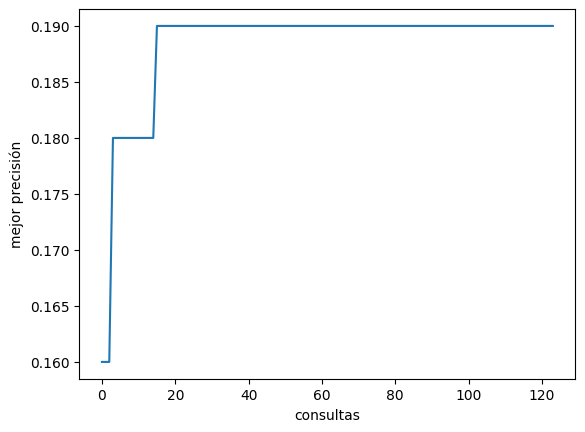

In [10]:
# ═══ CELDA F · Análisis de fallos: base vs. configuración final ═══
from collections import Counter
from ayudas import curva

r_final = oraculo.evaluar(mejor[1], INSTANCIAS, semilla=SEMILLA)   # sale del caché
f_final = Counter(t["violo"] for t in r_final.trazas)

familias = sorted(set(f_base) | set(f_final), key=lambda f: -f_base[f])
print(f"{'tipo de regla':42s} {'base':>5s} {'final':>6s} {'cambio':>7s}")
for f in familias:
    print(f"{f:42s} {f_base[f]:5d} {f_final[f]:6d} {f_final[f] - f_base[f]:+7d}")
print(f"\nPrecisión: base {p_base:.1%} -> final {mejor[0]:.1%}")
print(f"Evaluaciones totales: {len(registro)}  (= {len(registro) * 100} consultas al modelo)")

curva(historial)

## Validación final y entrega

`oraculo.validar` evalúa la configuración elegida sobre las 87 instancias de validación, que **no** se usaron para elegirla. Indica si la configuración funciona con instancias nuevas. No reemplaza la evaluación de la profesora, que usa un conjunto de prueba privado.

In [11]:
# ═══ CELDA G · Validación final y entrega.json ═══
import shutil
from ayudas import entrega
from google.colab import files

r_val = oraculo.validar(mejor[1], n=None)     # n=None = las 87 instancias de validación
print(f"\nBúsqueda (100 instancias):   {mejor[0]:.1%}")
print(f"Validación (87 instancias):  {r_val.precision:.1%}")

entrega(grupo="G01", config=mejor[1], semana=4)
shutil.copy("entrega.json", "/content/drive/MyDrive/entrega.json")   # copia de seguridad
files.download("entrega.json")

validación: 21.8%  (87 inst)
    8  punctuation:punctuation_dot
    6  last_word:last_word_sent
    5  copy:repeat_phrase
    4  first_word:first_word_sent
    4  letters:letter_counting
    4  length_constraints:nth_paragraph_first_word
    3  combination:repeat_prompt
    3  detectable_format:multiple_sections

Búsqueda (100 instancias):   18.0%
Validación (87 instancias):  21.8%
{
 "grupo": "G01",
 "config": {
  "rol": 3,
  "estrategia": 2,
  "formato": 0,
  "estilo": 3,
  "cierre": 3,
  "temperatura": 0.0
 },
 "semana": 4
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Curva de configuraciones completas y validación de la línea base

La curva incluye solo configuraciones con las cinco ranuras definidas, las únicas válidas para `entrega.json`. Va de 13 % (combinación de las mejores opciones individuales) a 17 % en la Fase 2 y a 18 % en la Fase 3: 83 configuraciones completas evaluadas.

Para que la validación tenga con qué compararse, se mide también el prompt sin instrucciones sobre las mismas 87 instancias:

| | Búsqueda (100) | Validación (87) |
|---|---|---|
| Sin instrucciones | 16,0 % | 17,2 % |
| Configuración final | 18,0 % | 21,8 % |

La configuración final acierta 4 instancias más en validación. La mejora se mantiene con instancias que no se usaron para elegirla, aunque con muestras de este tamaño (error típico de unos 4 puntos) no es estadísticamente concluyente.

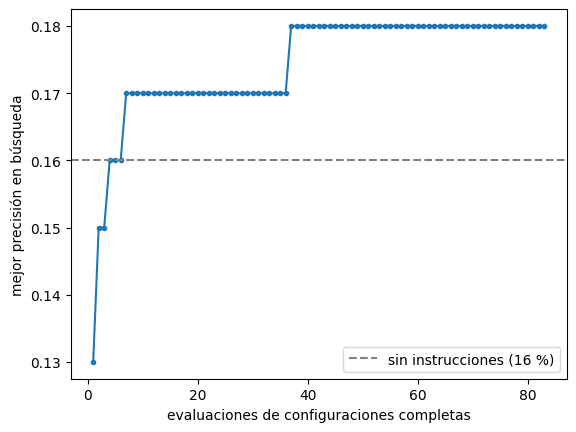

Configuraciones completas evaluadas: 83


validación: 17.2%  (87 inst)
    6  last_word:last_word_sent
    6  punctuation:punctuation_dot
    5  copy:repeat_phrase
    4  first_word:first_word_sent
    3  letters:letter_counting
    3  length_constraints:nth_paragraph_first_word
    3  keywords:frequency
    3  keywords:no_adjacent_consecutive

Validación sin instrucciones: 17.2%
Validación configuración final: 21.8%


In [12]:
# ═══ CELDA H · Curva con configuraciones completas y validación de la línea base ═══
import matplotlib.pyplot as plt

completas = [f for f in registro if all(f[s] != "-" for s in RANURAS)]
mejor_hasta, m = [], 0
for f in completas:
    m = max(m, f["precision"])
    mejor_hasta.append(m)
plt.plot(range(1, len(completas) + 1), mejor_hasta, marker=".")
plt.axhline(p_base, color="gray", linestyle="--", label="sin instrucciones (16 %)")
plt.xlabel("evaluaciones de configuraciones completas")
plt.ylabel("mejor precisión en búsqueda")
plt.legend()
plt.show()
print(f"Configuraciones completas evaluadas: {len(completas)}")

# ¿La mejora se mantiene con preguntas nuevas? Comparamos contra no poner nada
r_val_base = oraculo.validar({"temperatura": 0.0}, n=None)
print(f"\nValidación sin instrucciones: {r_val_base.precision:.1%}")
print(f"Validación configuración final: {r_val.precision:.1%}")
guardar_registro()

## Conclusión

| | |
|---|---|
| Configuración entregada (`entrega.json`) | rol 3 · estrategia 2 · formato 0 · estilo 3 · cierre 3 · temperatura 0.0 |
| Precisión en búsqueda | 18 % (sin instrucciones: 16 %) |
| Precisión en validación (`oraculo.validar`) | 21,8 % (sin instrucciones: 17,2 %) |
| Evaluaciones registradas | 124 de 32 768 posibles (0,38 %) |
| Garantía | Óptimo local respecto a cambiar una ranura; **no** es un óptimo global demostrado |

Hallazgo principal: las ranuras interactúan. Las mejores opciones individuales, combinadas, dieron 13 %, por debajo de la línea base; por eso fue necesario medir las opciones en contexto (Fase 3). La evaluación definitiva la hace la profesora sobre un conjunto de prueba privado con `evaluacion_G01.ipynb`.